# Model Training — Subset 1: Original Features

This notebook trains and tunes models on the **first feature subset**, the 26 original features from the raw dataset, with no engineered columns. This subset serves as our **baseline**: it tells us how well models perform when given only the raw scraped data, before any feature engineering was applied.

**Models trained:**

1. **Random Forest Regressor** — An ensemble of decision trees that averages many deep, de-correlated trees to reduce overfitting. It's robust to non-linear relationships and does not require feature scaling.

2. **XGBoost Regressor** — A gradient-boosted tree model that builds trees sequentially, each new tree correcting the errors of the previous ones. Often the strongest performer on tabular regression tasks.

**Why not Linear Regression here?** The original feature set contains correlated predictors (e.g., `rooms` and `areaSqm`) that can destabilise coefficient estimates. Tree-based models are immune to multicollinearity, making them a safer choice for this unfiltered feature set.

**Hyperparameter tuning** is performed via `RandomizedSearchCV`, which samples a fixed number of parameter combinations from a grid and evaluates each using cross-validation on the training set. More efficient than an exhaustive grid search when the parameter space is large.


In [1]:
import joblib
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV


In [2]:
X_train = pd.read_csv("subsets/train_original.csv")
y_train = pd.read_csv("subsets/train_target.csv")
X_val = pd.read_csv("subsets/val_original.csv")
y_val = pd.read_csv("subsets/val_target.csv")
X_train.head()


,airConditioning,alarm,areaSqm,balcony,bathrooms,closedParkingSpots,elevator,energyClass,fireplace,floor,...,livingRooms,openParkingSpots,petsAllowed,pool,renovationYear,rooms,solarHeater,storage,view,yearBuilt
0,1,0,3.688879,0,1.0,0.0,1,4,0,6,...,1.0,0.0,0,0,NaN,1.0,0,1,0,1971.0
1,1,0,4.007333,1,1.0,0.0,1,0,0,6,...,1.0,0.0,0,0,NaN,1.0,0,0,1,2025.0
2,1,0,4.248495,1,1.0,0.0,1,5,0,7,...,1.0,0.0,0,0,NaN,2.0,0,0,1,1978.0
3,1,1,4.317488,1,1.0,0.0,0,4,0,4,...,1.0,0.0,0,0,NaN,2.0,0,0,1,1960.0
4,1,0,3.951244,1,1.0,0.0,1,4,0,7,...,1.0,0.0,0,0,2023.0,1.0,0,0,1,1976.0


## Helper Function for Displaying Tuning Results

We define a `print_results()` utility that formats the output of `RandomizedSearchCV`:

- The **best CV score** and the parameter combination that achieved it.
- A ranked list of **all tried combinations**, each showing the mean CV score ± 2σ (a 95% confidence interval). This lets us assess whether the best configuration is significantly better than the runners-up or if differences are within noise.


In [3]:
def print_results(results):
    print(f"Best {results.best_score_} using {results.best_params_}\n")
    means = results.cv_results_["mean_test_score"]
    stds = results.cv_results_["std_test_score"]
    params = results.cv_results_["params"]
    for mean, std, param in zip(means, stds, params):
        print(f"{round(mean,3)} (+/-) {round(2*std,3)} {param}")


## Random Forest Regressor

### Hyperparameter Grid

We define the search space for the Random Forest:

- **`n_estimators`** (50–350, step 50): Number of trees in the ensemble. More trees generally improve performance up to a point, with diminishing returns and increased training time.
- **`max_depth`** (2, 4, 8, 16, 32, None): Maximum depth of each tree. `None` means unlimited. Shallow trees underfit while very deep trees or `None` may overfit.
- **`min_samples_split`** (2, 5): Minimum samples required to split an internal node. Higher values prevent overly specific splits that capture noise.
- **`max_features`** ('sqrt'): Number of features considered at each split. 'sqrt' is a common default for regression that introduces randomness between trees, improving generalisation.

### Fitting via RandomizedSearchCV

We use `scoring='neg_mean_squared_error'` because scikit-learn's CV framework always **maximises** the score. By negating the MSE, a lower error becomes a higher score, so the "best" result corresponds to the lowest MSE.


In [4]:
rf = RandomForestRegressor()
parameters = {
    "n_estimators": [i for i in range(50, 400, 50)],
    "max_depth": [2, 4, 8, 16, 32, None],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt"]
}

rf_cv = RandomizedSearchCV(rf, parameters, scoring="neg_mean_squared_error")
rf_cv.fit(X_train, y_train.values.ravel())

print_results(rf_cv)


Best -0.031081957354458845 using {'n_estimators': 250, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': 32}

-0.032 (+/-) 0.005 {'n_estimators': 200, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': None}
-0.047 (+/-) 0.005 {'n_estimators': 300, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 4}
-0.031 (+/-) 0.006 {'n_estimators': 250, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': 32}
-0.036 (+/-) 0.006 {'n_estimators': 150, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': 8}
-0.063 (+/-) 0.005 {'n_estimators': 50, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 2}
-0.063 (+/-) 0.004 {'n_estimators': 350, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': 2}
-0.032 (+/-) 0.006 {'n_estimators': 50, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 16}
-0.063 (+/-) 0.004 {'n_estimators': 100, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': 2}
-0.035 (+/-) 0.005 {'n_estimators': 

## XGBoost Regressor

### Hyperparameter Grid

We define a separate search space for XGBoost, which has a different set of tunable parameters:

- **`n_estimators`** (50–450, step 50): Number of boosting rounds (trees). XGBoost typically benefits from more rounds than Random Forest, but too many can overfit without proper regularisation.
- **`max_depth`** (2, 4, 8, 16, 32, None): Maximum depth of each tree. XGBoost trees are generally shallower than Random Forest trees because each tree only needs to correct the residual errors.
- **`learning_rate`** (0.1, 0.01, 0.001): Step size shrinkage used after each boosting step. Lower values make the model more robust by requiring more trees, but increase training time. 0.1 is a common starting point.
- **`subsample`** (0.5, 0.7, 1.0): Fraction of training rows randomly sampled to grow each tree. Values < 1.0 introduce row-level stochasticity, which helps prevent overfitting.


In [5]:
xgb = XGBRegressor()
parameters = {
    "n_estimators": [i for i in range(50, 500, 50)],
    "max_depth": [2, 4, 8, 16, 32, None],
    "learning_rate": [0.1, 0.01, 0.001],
    "subsample": [0.5, 0.7, 1]
}

xgb_cv = RandomizedSearchCV(xgb, parameters, scoring="neg_mean_squared_error")
xgb_cv.fit(X_train, y_train.values.ravel())

print_results(xgb_cv)


Best -0.03060452603674797 using {'subsample': 0.5, 'n_estimators': 450, 'max_depth': 8, 'learning_rate': 0.01}

-0.035 (+/-) 0.006 {'subsample': 1, 'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.01}
-0.032 (+/-) 0.006 {'subsample': 1, 'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.1}
-0.052 (+/-) 0.005 {'subsample': 1, 'n_estimators': 150, 'max_depth': 2, 'learning_rate': 0.01}
-0.067 (+/-) 0.003 {'subsample': 0.7, 'n_estimators': 50, 'max_depth': 4, 'learning_rate': 0.01}
-0.031 (+/-) 0.006 {'subsample': 0.5, 'n_estimators': 450, 'max_depth': 8, 'learning_rate': 0.01}
-0.031 (+/-) 0.005 {'subsample': 1, 'n_estimators': 300, 'max_depth': 2, 'learning_rate': 0.1}
-0.079 (+/-) 0.003 {'subsample': 1, 'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.001}
-0.031 (+/-) 0.006 {'subsample': 0.5, 'n_estimators': 400, 'max_depth': 8, 'learning_rate': 0.01}
-0.035 (+/-) 0.008 {'subsample': 0.5, 'n_estimators': 400, 'max_depth': 32, 'learning_rate': 0.1}
-0.083 (+/-) 0.003

## Feature Importance Comparison

Both Random Forest and XGBoost provide a **feature_importances_** attribute after fitting. This attribute measures how much each feature contributed to reducing the impurity (Random Forest) or the loss (XGBoost) across all trees. By extracting and sorting these values, we can identify which of the 26 original features the models rely on most.

We create two DataFrames (one per model), sort them by importance in descending order, and plot them side by side for easy comparison. Features that appear at the top of both lists are strong candidates for the "important features" subset.


In [6]:
# Random Forest feature importance
rf_feat_imp = rf_cv.best_estimator_.feature_importances_
rf_imp_dict = {"Feature RF" : list(X_train.columns),
        "Feature Importance RF" : rf_feat_imp}
rf_importance = pd.DataFrame(rf_imp_dict)
rf_sorting_features = rf_importance.sort_values(by=["Feature Importance RF"], ascending=False)

# XGBoost feature importance
xgb_feat_imp = xgb_cv.best_estimator_.feature_importances_
xgb_imp_dict = {"Feature XGB" : list(X_train.columns),
        "Feature Importance XGB" : xgb_feat_imp}
xgb_importance = pd.DataFrame(xgb_imp_dict)
xgb_sorting_features = xgb_importance.sort_values(by=["Feature Importance XGB"], ascending=False)


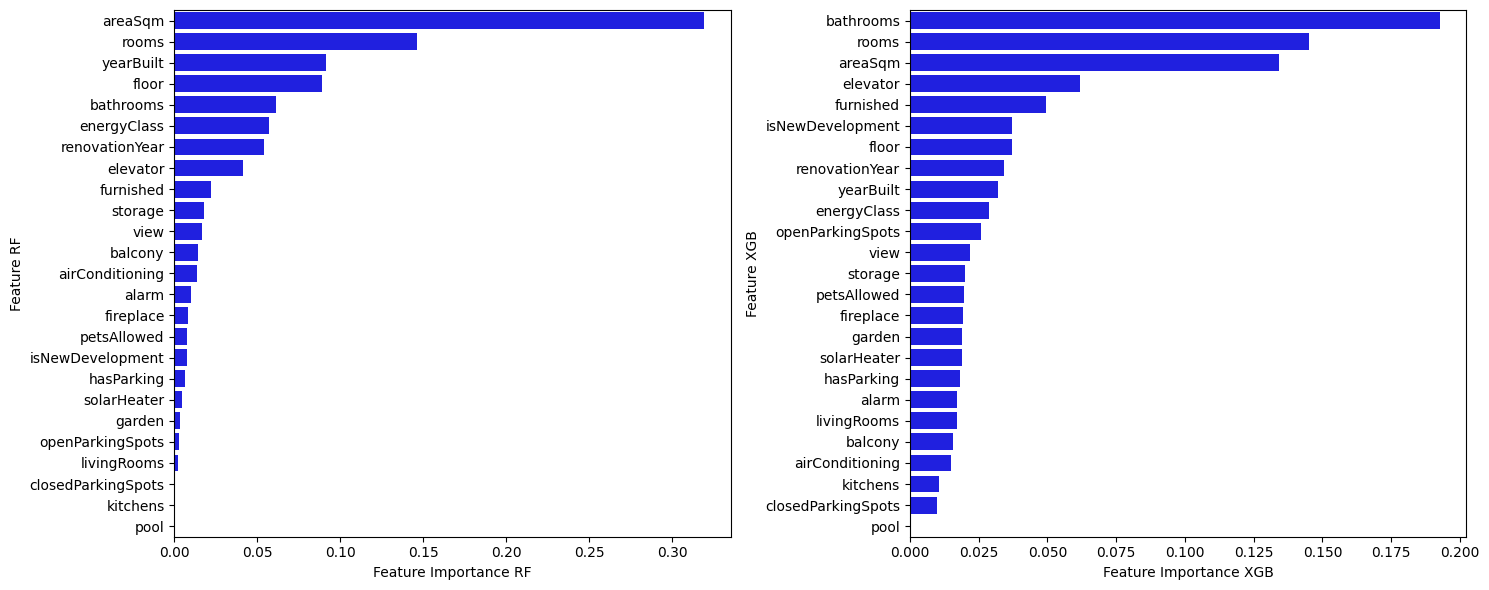

In [7]:
# plotting feature importance graph
fig,ax = plt.subplots(1,2, figsize=(15,6))
bar = sns.barplot(x="Feature Importance RF", y="Feature RF", data=rf_sorting_features, color="blue", ax=ax[0])
bar = sns.barplot(x="Feature Importance XGB", y="Feature XGB", data=xgb_sorting_features, color="blue", ax=ax[1])

plt.tight_layout()
plt.show()


## Saving the Trained Models

We serialise the best-performing Random Forest and XGBoost models using `joblib.dump()`. The `.pkl` files are saved to a `models/` directory. These saved models can later be loaded by the evaluation notebook to compute metrics on the test set, without needing to retrain.

| File | Model | Features Used |
|---|---|---|
| `model_rf_original.pkl` | Best Random Forest (tuned) | 26 original features |
| `model_xgb_original.pkl` | Best XGBoost (tuned) | 26 original features |


In [8]:
joblib.dump(rf_cv.best_estimator_, "models/model_rf_original.pkl")
joblib.dump(xgb_cv.best_estimator_, "models/model_xgb_original.pkl")


['models/model_xgb_original.pkl']